# Monte Carlo Neutronics of a PWR Fuel Pin with OpenMC and pandas
This notebook builds an infinite-lattice PWR UO₂ pin cell (reflective boundaries), solves the k-eigenvalue
problem with OpenMC's continuous-energy Monte Carlo solver, and analyses the tallies systematically with
pandas DataFrames. It is a modernised, heavily annotated counterpart of the official
`openmc-notebooks/pandas-dataframes.ipynb`, updated for OpenMC ≥ 0.16 (Model API, source constraints).

**Learning goals:** the neutron transport equation → Monte Carlo random walks → power iteration and k_eff →
inactive/active batches and Shannon entropy → tallies, estimators and uncertainties → pandas analysis.

## 1. The neutron transport equation
The angular flux ψ(r, Ω, E) (neutrons·cm⁻²·s⁻¹·sr⁻¹·eV⁻¹) obeys the steady-state Boltzmann equation:

$$\Omega\cdot\nabla\psi + \Sigma_t(\mathbf r,E)\psi = \int_0^\infty\!\!\int_{4\pi}\Sigma_s(\mathbf r,E'\to E,\Omega'\to\Omega)\psi\,d\Omega' dE' + \frac{\chi(E)}{4\pi k}\int_0^\infty \nu\Sigma_f(\mathbf r,E')\phi(\mathbf r,E')\,dE'$$

- Σ_x = N σ_x is a macroscopic cross section (cm⁻¹): atom density N (atoms/b-cm) × microscopic cross section σ_x (barns).
- φ = ∫ψ dΩ is the scalar flux, ν is neutrons per fission, χ(E) is the fission spectrum.
- With no external source this is an **eigenvalue problem**: only the factor 1/k makes a steady state possible.
  k_eff > 1 is supercritical, = 1 critical, < 1 subcritical.

Monte Carlo does not discretise this equation. Instead it simulates individual neutron histories whose
*expected* behaviour satisfies it exactly: distance to collision ~ Exp(Σ_t), the collision nuclide is chosen
∝ Σ_{t,i}, and the reaction ∝ σ_x/σ_t, all with continuous-energy nuclear data.

In [2]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openmc

print("OpenMC version:", openmc.__version__)

# Cross-section data: OpenMC reads a cross_sections.xml index pointing to HDF5 files.
# openmc.config['cross_sections'] is initialised from $OPENMC_CROSS_SECTIONS at import time.
xs = os.environ.get("OPENMC_CROSS_SECTIONS")
if xs is None:
    # Fallback: edit this path to where tar data is unpacked i.e. the ENDF/B-VIII.0 library from openmc.org/data
    xs = str(Path.home() / "nuclear_data" / "endfb-viii.0-hdf5" / "cross_sections.xml")
openmc.config["cross_sections"] = xs
assert Path(openmc.config["cross_sections"]).exists(), "cross_sections.xml not found - see README"

workdir = Path("run_pincell"); workdir.mkdir(exist_ok=True)

OpenMC version: 0.16.0


## 2. Nuclear data and cross sections
Evaluated libraries (ENDF/B-VIII.0, JEFF, JENDL) are processed by NJOY into OpenMC's HDF5 format. Each nuclide
file holds pointwise σ(E) at several temperatures (250–2500 K for the official libraries), resonance
probability tables, secondary angle/energy distributions, and ν(E). **Thermal scattering S(α,β)** data
(`c_H_in_H2O`) captures the effect of molecular binding of hydrogen in water below ~4 eV. Leaving it out
(as the original pandas notebook does) visibly distorts the thermal spectrum and k_eff.

In [4]:
# Composition follows the official examples/pincell/build_xml.py (2.4 wt% UO2, Zircaloy-4, borated water)
uo2 = openmc.Material(name="UO2 fuel 2.4 wt%")
uo2.set_density("g/cm3", 10.29769)
uo2.add_element("U", 1.0, enrichment=2.4)    # enrichment in wt% U-235
uo2.add_element("O", 2.0)
uo2.temperature = 900                        # K, approximate fuel temperature

helium = openmc.Material(name="He gap")
helium.set_density("g/cm3", 0.001598)
helium.add_element("He", 2.4044e-4)

zircaloy = openmc.Material(name="Zircaloy-4")
zircaloy.set_density("g/cm3", 6.55)
zircaloy.add_element("Sn", 0.014, "wo")
zircaloy.add_element("Fe", 0.00165, "wo")
zircaloy.add_element("Cr", 0.001, "wo")
zircaloy.add_element("Zr", 0.98335, "wo")

water = openmc.Material(name="Borated water")
water.set_density("g/cm3", 0.740582)
water.add_element("B", 4.0e-5)
water.add_element("H", 5.0e-2)
water.add_element("O", 2.4e-2)
water.add_s_alpha_beta("c_H_in_H2O")

materials = openmc.Materials([uo2, helium, zircaloy, water])
for m in materials:
    print(m.name, {k: f"{v:.3e}" for k, v in m.get_nuclide_atom_densities().items()})

UO2 fuel 2.4 wt% {'U234': '4.989e-06', 'U235': '5.582e-04', 'U238': '2.240e-02', 'U236': '2.557e-06', 'O16': '4.583e-02', 'O17': '1.741e-05', 'O18': '9.190e-05'}
He gap {'He3': '4.809e-10', 'He4': '2.404e-04'}
Zircaloy-4 {'Sn112': '4.512e-06', 'Sn114': '3.070e-06', 'Sn115': '1.582e-06', 'Sn116': '6.764e-05', 'Sn117': '3.573e-05', 'Sn118': '1.127e-04', 'Sn119': '3.996e-05', 'Sn120': '1.516e-04', 'Sn122': '2.154e-05', 'Sn124': '2.693e-05', 'Fe54': '6.812e-06', 'Fe56': '1.069e-04', 'Fe57': '2.470e-06', 'Fe58': '3.287e-07', 'Cr50': '3.296e-06', 'Cr52': '6.356e-05', 'Cr53': '7.208e-06', 'Cr54': '1.794e-06', 'Zr90': '2.188e-02', 'Zr91': '4.771e-03', 'Zr92': '7.292e-03', 'Zr94': '7.390e-03', 'Zr96': '1.191e-03'}
Borated water {'B10': '8.132e-06', 'B11': '3.290e-05', 'H1': '5.128e-02', 'H2': '7.987e-06', 'O16': '2.456e-02', 'O17': '9.330e-06', 'O18': '4.924e-05'}


`add_element` expands natural elements into isotopes using IUPAC abundances, and only keeps isotopes present
in your cross-section library. `get_nuclide_atom_densities()` returns atoms/b-cm, i.e. the N in Σ = Nσ.
Note on temperature: OpenMC interpolates between the library temperatures (default method 'nearest'). See
`Settings.temperature` if you need interpolation.

## 3. Constructive solid geometry (CSG)
Surfaces define half-spaces (−S inside, +S outside). Cells are Boolean combinations of half-spaces filled with
materials. A `RectangularPrism` with `boundary_type='reflective'` mirrors every neutron that reaches the outer
boundary. Physically this models an **infinite lattice of identical pins**, so there is zero net leakage and the
result is k_∞ rather than k_eff of a finite core.

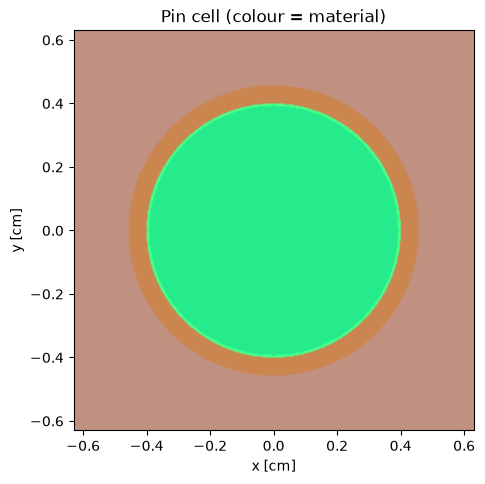

In [5]:
pitch = 1.25984
fuel_or = openmc.ZCylinder(r=0.39218, name="Fuel OR")
clad_ir = openmc.ZCylinder(r=0.40005, name="Clad IR")
clad_or = openmc.ZCylinder(r=0.45720, name="Clad OR")
box = openmc.model.RectangularPrism(pitch, pitch, boundary_type="reflective")

fuel_cell = openmc.Cell(name="fuel", fill=uo2,      region=-fuel_or)
gap_cell  = openmc.Cell(name="gap",  fill=helium,   region=+fuel_or & -clad_ir)
clad_cell = openmc.Cell(name="clad", fill=zircaloy, region=+clad_ir & -clad_or)
mod_cell  = openmc.Cell(name="moderator", fill=water, region=+clad_or & -box)

geometry = openmc.Geometry([fuel_cell, gap_cell, clad_cell, mod_cell])
uo2.volume = np.pi * fuel_or.r**2        # per unit height; used for volume-averaged quantities
geometry.root_universe.plot(width=(pitch, pitch), pixels=(400, 400), color_by="material")
plt.title("Pin cell (colour = material)"); plt.show()

## 4. k-eigenvalue: power iteration, batches, Shannon entropy
OpenMC uses the **method of successive generations**. Each generation tracks N neutrons, banks fission sites
(expected number w·νΣ_f/(kΣ_t) per collision), then resamples N sites as the next generation's source. This is
the stochastic analogue of power iteration, $S^{(n+1)} = \tfrac{1}{k^{(n)}}\mathcal{F}S^{(n)}$, and it
converges to the fundamental mode at a rate set by the dominance ratio k₁/k₀.

- **Inactive batches** discard results while the source converges from the initial guess.
  Tallying them would bias the results.
- **Active batches** each give one independent realisation of every tally (batch statistics).
- **Shannon entropy** $H=-\sum_i S_i\log_2 S_i$ over a mesh turns the source distribution into a scalar.
  When H flattens out, the source has converged. The docs warn that the source converges more slowly than k_eff.
- k_eff is reported as a combination of the collision, absorption and track-length estimators.

In [6]:
settings = openmc.Settings()
settings.run_mode = "eigenvalue"
settings.batches = 150
settings.inactive = 30
settings.particles = 10_000

ll, ur = (-pitch/2, -pitch/2, -1), (pitch/2, pitch/2, 1)
settings.source = openmc.IndependentSource(
    space=openmc.stats.Box(ll, ur),
    constraints={"fissionable": True})       # replaces the deprecated only_fissionable=True/ older version of OpenMC

entropy_mesh = openmc.RegularMesh()
entropy_mesh.lower_left = (-fuel_or.r, -fuel_or.r)
entropy_mesh.upper_right = (fuel_or.r, fuel_or.r)
entropy_mesh.dimension = (10, 10)
settings.entropy_mesh = entropy_mesh
settings.seed = 1                            # reproducibility

## 5. Tallies: filters × nuclides × scores
Every tally is $X=\int_{\text{filters}} f(\mathbf r,\Omega,E)\,\psi\,d\mathbf r\,d\Omega\,dE$.
**Filters** set the integration domain (cell, material, energy bins, mesh). **Scores** set f: `flux`
(f = 1), `total`, `scatter`, `absorption`, `fission` (Σ_f), `nu-fission` (νΣ_f), and so on.

Estimators:
- analog: $R_x=\frac1W\sum_{i\in A}w_i$, counting actual reactions
- collision: $R_x=\frac1W\sum_{i\in C}w_i\Sigma_x/\Sigma_t$
- track-length: $R_x=\frac1W\sum_{i\in T}w_i\ell_i\Sigma_x$, which scores on every flight path and usually has the lowest variance

Units: results are **per source neutron**. Flux comes out as track length (cm) per source particle; divide by
volume for cm⁻². To get absolute values (n·cm⁻²·s⁻¹), multiply by the source rate derived from the power.

Energy groups: we use a 2-group split at 0.625 eV (thermal/fast, as in the original notebook) and a
logarithmic 300-bin grid to resolve the spectrum.

In [7]:
two_group = openmc.EnergyFilter([0.0, 0.625, 20.0e6])
fine = openmc.EnergyFilter(np.logspace(-5, np.log10(20e6), 301))   # 1e-5 eV .. 20 MeV
cell_f = openmc.CellFilter([fuel_cell, clad_cell, mod_cell])
mat_f = openmc.MaterialFilter([uo2])

t_spec = openmc.Tally(name="flux spectrum")
t_spec.filters = [openmc.CellFilter([fuel_cell, mod_cell]), fine]
t_spec.scores = ["flux"]

t_rr = openmc.Tally(name="fuel reaction rates")
t_rr.filters = [mat_f, two_group]
t_rr.nuclides = ["U235", "U238", "O16"]
t_rr.scores = ["total", "scatter", "absorption", "fission", "nu-fission"]

t_cells = openmc.Tally(name="cell 2-group")
t_cells.filters = [cell_f, two_group]
t_cells.scores = ["flux", "absorption"]

mesh = openmc.RegularMesh()
mesh.lower_left, mesh.upper_right, mesh.dimension = (-pitch/2, -pitch/2), (pitch/2, pitch/2), (50, 50)
t_mesh = openmc.Tally(name="mesh")
t_mesh.filters = [openmc.MeshFilter(mesh), two_group]
t_mesh.scores = ["flux", "fission"]

tallies = openmc.Tallies([t_spec, t_rr, t_cells, t_mesh])

In [8]:
model = openmc.Model(geometry=geometry, materials=materials, settings=settings, tallies=tallies)
sp_path = model.run(cwd=workdir)          # exports model.xml, runs openmc, returns last statepoint path
print("Statepoint:", sp_path)

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

`Model.run()` writes `model.xml` in `run_pincell/`, runs the `openmc` executable, and returns the path to
`statepoint.150.h5`. Equivalent legacy workflow: `materials.export_to_xml(); geometry.export_to_xml(); ...;
openmc.run()`. A `summary.h5` file is also written, so cells and materials appear with their names in the
DataFrames.

k_inf = 1.14116 ± 0.00090  (90 pcm)


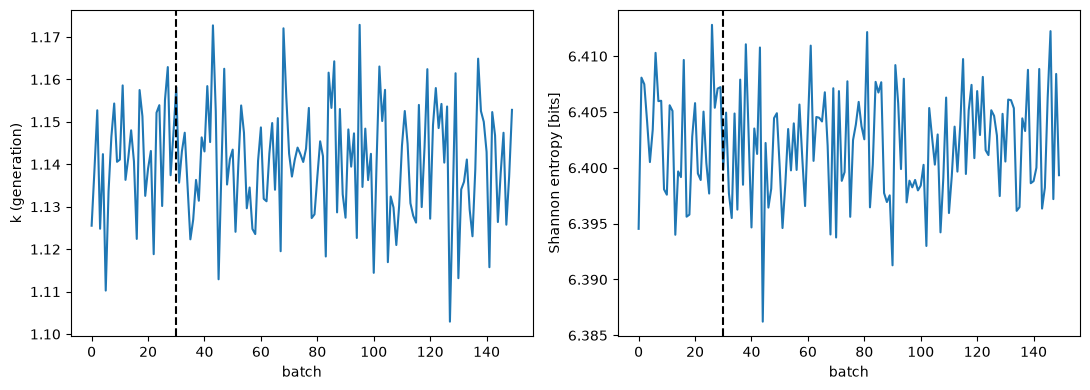

In [9]:
with openmc.StatePoint(sp_path) as sp:
    keff = sp.keff                            # uncertainties.UFloat: combined estimator
    k_gen = np.array(sp.k_generation)
    entropy = np.array(sp.entropy)
    n_inactive = sp.n_inactive
    spec = sp.get_tally(name="flux spectrum")
    rr = sp.get_tally(name="fuel reaction rates")
    cells = sp.get_tally(name="cell 2-group")
    mtal = sp.get_tally(name="mesh")
    df_spec = spec.get_pandas_dataframe()
    df_rr = rr.get_pandas_dataframe()
    df_cells = cells.get_pandas_dataframe()
    df_mesh = mtal.get_pandas_dataframe()

print(f"k_inf = {keff.nominal_value:.5f} ± {keff.std_dev:.5f}  ({1e5*keff.std_dev:.0f} pcm)")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(k_gen); ax[0].axvline(n_inactive, ls="--", c="k"); ax[0].set(xlabel="batch", ylabel="k (generation)")
ax[1].plot(entropy); ax[1].axvline(n_inactive, ls="--", c="k"); ax[1].set(xlabel="batch", ylabel="Shannon entropy [bits]")
plt.tight_layout(); plt.show()

**Reading these plots.** The generation-wise k fluctuates around the mean. Its scatter shrinks only as 1/√N
per batch, while the uncertainty of the *mean* shrinks as $1/\sqrt{N\,n_{active}}$. Entropy should reach a
plateau well before the dashed line (the end of the inactive batches). If it is still trending, increase
`settings.inactive`. Expect k_∞ ≈ 1.2–1.3 for 2.4% fuel in an infinite lattice. A large difference between
libraries or settings is physics, not a bug.
Caveat: batch-to-batch correlation in power iteration makes the reported σ of local tallies somewhat
**underestimate** the true uncertainty. This is a well-known limitation of eigenvalue Monte Carlo.

## 6. Anatomy of a tally DataFrame
`Tally.get_pandas_dataframe()` returns one row per (filter-bin combination × nuclide × score), with columns
for each filter (e.g. `cell`, `material`, `energy low [eV]`, `energy high [eV]`, `mesh 1 (x/y)`), then
`nuclide`, `score`, `mean` and `std. dev.`. This "long" (tidy) format is exactly what `query`, `groupby` and
`pivot_table` expect.

In [10]:
pd.set_option("display.float_format", "{:.4e}".format)
df_rr["rel. err."] = df_rr["std. dev."] / df_rr["mean"]
display(df_rr.head(12))
print(df_rr.columns.tolist())

,material,energy low [eV],energy high [eV],nuclide,score,mean,std. dev.,rel. err.
0,1,0.0000e+00,6.2500e-01,U235,total,4.6475e-01,6.0487e-04,1.3015e-03
1,1,0.0000e+00,6.2500e-01,U235,scatter,1.5133e-02,1.8367e-05,1.2137e-03
2,1,0.0000e+00,6.2500e-01,U235,absorption,4.4961e-01,5.8785e-04,1.3074e-03
3,1,0.0000e+00,6.2500e-01,U235,fission,3.8278e-01,5.0152e-04,1.3102e-03
4,1,0.0000e+00,6.2500e-01,U235,nu-fission,9.3020e-01,1.2187e-03,1.3101e-03
5,1,0.0000e+00,6.2500e-01,U238,total,4.7923e-01,5.8182e-04,1.2141e-03
6,1,0.0000e+00,6.2500e-01,U238,scatter,4.0453e-01,4.9031e-04,1.2120e-03
7,1,0.0000e+00,6.2500e-01,U238,absorption,7.4697e-02,9.6507e-05,1.2920e-03
8,1,0.0000e+00,6.2500e-01,U238,fission,5.1423e-07,6.6497e-10,1.2931e-03
9,1,0.0000e+00,6.2500e-01,U238,nu-fission,1.2563e-06,1.6245e-09,1.2931e-03


['material', 'energy low [eV]', 'energy high [eV]', 'nuclide', 'score', 'mean', 'std. dev.', 'rel. err.']


### Filtering, grouping, pivoting
Below we (1) select thermal fission, (2) pivot to a nuclide × score table, and (3) compute derived physics:
- η (neutrons per absorption in fuel) = νΣ_f / Σ_a
- the thermal fission fraction

Uncertainties of ratios are propagated to first order, assuming no correlation (a conservative simplification).
For correlated arithmetic, use `Tally` arithmetic (`t1 / t2`) instead.

In [11]:
thermal = df_rr[df_rr["energy high [eV]"] <= 0.625]
print(thermal.query("score == 'fission'")[["nuclide", "mean", "rel. err."]])

pivot = df_rr.pivot_table(index="nuclide", columns="score", values="mean", aggfunc="sum")  # sums over both groups
display(pivot)

tot = df_rr.groupby("score")[["mean"]].sum()
eta = tot.loc["nu-fission", "mean"] / tot.loc["absorption", "mean"]
fis = df_rr.query("score=='fission'").groupby("energy high [eV]")["mean"].sum()
print(f"eta (fuel) = {eta:.4f};  thermal fission fraction = {fis.iloc[0]/fis.sum():.3f}")
print("U-238 share of fuel absorption:", pivot.loc["U238", "absorption"] / pivot["absorption"].sum())

   nuclide       mean  rel. err.
3     U235 3.8278e-01 1.3102e-03
8     U238 5.1423e-07 1.2931e-03
13     O16 0.0000e+00        NaN


score,absorption,fission,nu-fission,scatter,total
nuclide,,,,,
O16,2.1067e-03,0.0000e+00,0.0000e+00,2.0648e+00,2.0669e+00
U235,5.2951e-01,4.3687e-01,1.0619e+00,7.0542e-02,6.0006e-01
U238,3.0814e-01,2.8307e-02,7.8553e-02,2.9393e+00,3.2475e+00


eta (fuel) = 1.3581;  thermal fission fraction = 0.823
U-238 share of fuel absorption: 0.3669365615325476


**Interpretation.** Most fissions are in U-235 and are thermal. U-238 contributes the fast-fission share and a
large share of absorption (resonance capture), which is the origin of the resonance-escape factor p in the
four-factor formula $k_\infty=\eta f p \varepsilon$.

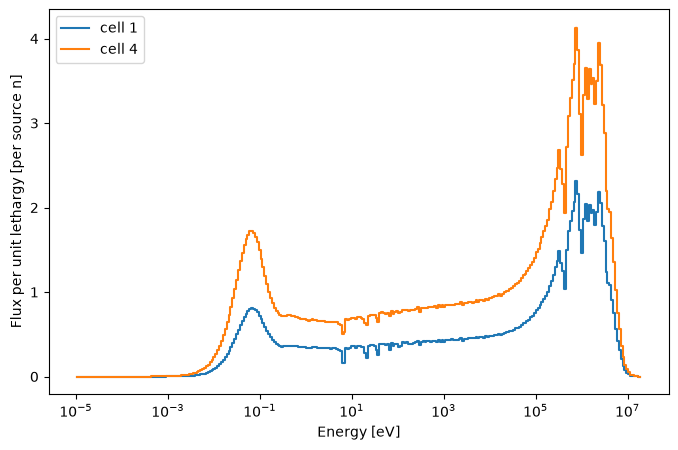

In [12]:
df_spec["E_mid"] = np.sqrt(df_spec["energy low [eV]"].clip(lower=1e-5) * df_spec["energy high [eV]"])
df_spec["lethargy width"] = np.log(df_spec["energy high [eV]"] / df_spec["energy low [eV]"].clip(lower=1e-5))
df_spec["flux/u"] = df_spec["mean"] / df_spec["lethargy width"]
fig, ax = plt.subplots(figsize=(8, 5))
for cell_id, g in df_spec.groupby("cell"):
    ax.step(g["E_mid"], g["flux/u"], where="mid", label=f"cell {cell_id}")
    ax.fill_between(g["E_mid"], g["flux/u"] - g["std. dev."]/g["lethargy width"],
                    g["flux/u"] + g["std. dev."]/g["lethargy width"], step="mid", alpha=0.3)
ax.set(xscale="log", xlabel="Energy [eV]", ylabel="Flux per unit lethargy [per source n]")
ax.legend(); plt.show()